# <U>**Phase 1:**</U>

In [1]:
import numpy as np
import csv 
import pandas as pd


file = open("heart.csv")
reader = csv.reader(file)
data = list(reader)

data = pd.read_csv("heart.csv")



## **Data Preparation**

1. **Slit data**
2. **Visualization**
3. **Rescaling**
4. **Handeling caregorical features**
5. **Feature engineering**


## visualization

Results:
this is approximaitly uniform distribution and that is acceptable
Note that wwe should check the "feature value distribiution /correlation between feature / seprebality of classes" 
assume that these concept is accepted
Scaling: in this dataset no need to scaling cause the values are in the same order.

## Data Preparation: Error Correction

1. Handling Missing Values
2. Handling Inconsistent Values
3. Handling Outliers
4. Handling Categorical Values


## 1, 2, 3:

In [2]:
data.isna().sum()             #so there in no nan(null) value in dataset



Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

In [3]:
print(data.describe())  
print("\n") 
print("Number of missing value of Cholesterol: ",(data["Cholesterol"] == 0).sum())  
print("Number of missing value of RestingBP: ",(data["RestingBP"] == 0).sum())     


              Age   RestingBP  Cholesterol   FastingBS       MaxHR  \
count  918.000000  918.000000   918.000000  918.000000  918.000000   
mean    53.510893  132.396514   198.799564    0.233115  136.809368   
std      9.432617   18.514154   109.384145    0.423046   25.460334   
min     28.000000    0.000000     0.000000    0.000000   60.000000   
25%     47.000000  120.000000   173.250000    0.000000  120.000000   
50%     54.000000  130.000000   223.000000    0.000000  138.000000   
75%     60.000000  140.000000   267.000000    0.000000  156.000000   
max     77.000000  200.000000   603.000000    1.000000  202.000000   

          Oldpeak  HeartDisease  
count  918.000000    918.000000  
mean     0.887364      0.553377  
std      1.066570      0.497414  
min     -2.600000      0.000000  
25%      0.000000      0.000000  
50%      0.600000      1.000000  
75%      1.500000      1.000000  
max      6.200000      1.000000  


Number of missing value of Cholesterol:  172
Number of missin

# **Results:**

- The dataset contains **inconsistent values** in the following features:
  - **RestingBP**
  - **Cholesterol**

- The dataset does **not contain significant outliers**.

- Missing values summary:
  - **172 missing values** in the **Cholesterol** feature
  - **1 missing value** in the **RestingBP** feature

# **Analysis:**

### **Handling Missing Values:**

Three standard approaches were considered for handling missing values:

#### **1. Deletion**
This method removes samples or features containing missing values.  
Although simple to implement, deletion was not selected for features with a large number of missing values because it would significantly reduce the dataset size and potentially discard valuable medical information.

#### **2. Simple Imputation**
Missing values are replaced using statistical measures such as the **mean**, **median**, or **mode**.  
This approach is easy to interpret and commonly used in medical datasets. It preserves the dataset size while avoiding unnecessary complexity.

#### **3. Advanced Model-Based Imputation**
Methods such as **KNN Imputer** or **Iterative Imputer** estimate missing values using relationships between features (e.g., linear regression).  
While potentially more accurate, these methods introduce additional complexity, require careful feature scaling, and increase the risk of information leakage.

## **Selected Strategy and Justification**

**Cholesterol:** Median imputation was selected for the Cholesterol feature. Cholesterol values are continuous and may contain outliers; therefore,
 the median provides a robust estimate that is less sensitive to extreme values compared to the mean. This method preserves all patient records and 
 avoids information leakage by not using the target variable during imputation.

**RestingBP:** Only one missing value was detected for the RestingBP feature. Given the negligible proportion of missing data and the absence 
of explicit medical guidelines for imputation, the corresponding record was removed. This conservative approach avoids introducing assumptions 
that could bias the model.


In [4]:
data = data[data["RestingBP"] != 0]                                              #Deletion 

data["Cholesterol"] = data["Cholesterol"].replace(0, np.nan)
median_chol = data["Cholesterol"].median()
data["Cholesterol"] = data["Cholesterol"].fillna(median_chol)                  #median impution



# 4. Handeling categorical values

In [5]:
data.select_dtypes(include="object").columns

C:\Users\av laptop\AppData\Local\Temp\ipykernel_18268\1271515388.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  data.select_dtypes(include="object").columns


Index(['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope'], dtype='str')

1. **sex** = Label encoding (cause it is binary and no ordination 1 or 0)
2. **ChestpainType** = One-Hot encoding (it has 4 categories with no medical ordination if we use e.g. ordinal encoding we add extera and wrong information to model)
3. **RestingECG** = One-Hot encoding (like ChestPainType)
4. **ExerciseAngina** = Label encoding (Like sex)
5. **ST_Slope** = Ordinal Encoding (It has medical ordination Up > Flat > Down)

In [6]:
#sex label encoding
data["Sex"] = data["Sex"].map({"M": 1, "F": 0})  

#chestpain type one hot encoding
data = pd.get_dummies(data, columns=["ChestPainType"], drop_first = False)                    #cause one of)

#RestingECG one hot encoding
data = pd.get_dummies(data, columns=["RestingECG"], drop_first=False)

#Excersise Angina Label encoding
data["ExerciseAngina"] = data["ExerciseAngina"].map({"Y": 1, "N": 0})

#ST_Slope ordinal encoding
data["ST_Slope"] = data["ST_Slope"].map({"Down": 0,"Flat": 1,"Up": 2})

#convert boolian type to binary
bool_cols = data.select_dtypes(include="bool").columns
data[bool_cols] = data[bool_cols].astype(int)

## **Visualization**
#### 1. **Class label distribiution** (not wanted)
#### 2. **Feature value distribiution**  (not wanted)
#### 3. **correlation between features**
#### 4. **Sepraboloty of classes**   (not wanted)

## **3:**

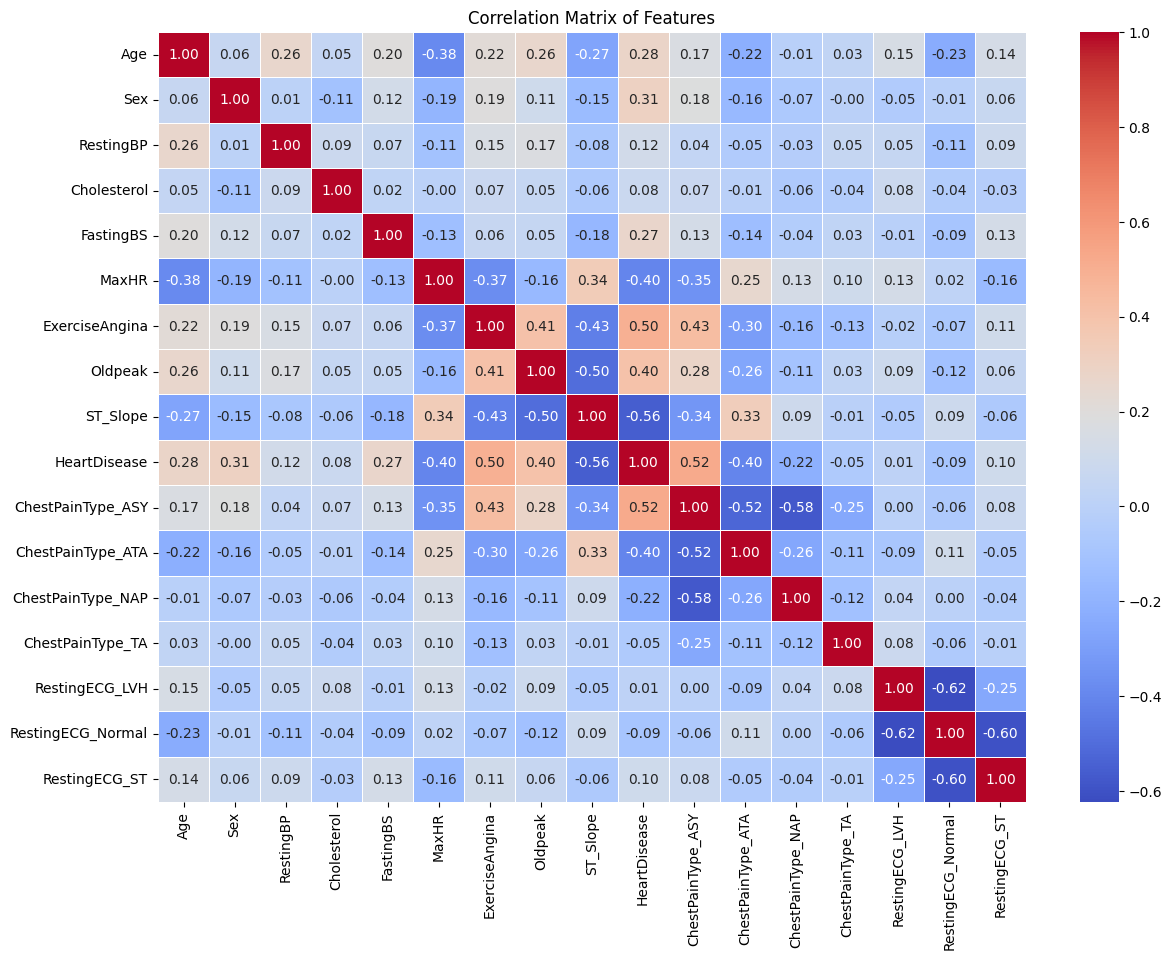

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

corr_matrix = data.corr()

plt.figure(figsize=(14, 10))
sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    annot=True,      
    fmt=".2f",       
    linewidths=0.5   
)

plt.title("Correlation Matrix of Features")
plt.show()



### **Analysis**
Correlation analysis was used as an exploratory tool to understand linear relationships between features and the target variable. However, due to the use of non-linear models, no aggressive feature elimination was performed.

The correlation matrix shows that features such as MaxHR(-0.40), Sex(0.31), Age(0.28), ST_Slope(-0.56), and FastingBS(0.27) have moderate to strong correlations with the target variable HeartDisease. Some features, including Cholesterol(0.08) and RestingBP(0.12), exhibit weak linear correlations; however, they were retained due to their clinical relevance and the potential presence of non-linear relationships. No pairs of features showed extremely high inter-correlation that would justify feature removal.

---


# <U>**Phase 2:**</U>

### 1. Test-Train split
20% test 80%train
randomly and keep the class distribution in test and train dataset(stratify = y)

In [8]:
from sklearn.model_selection import train_test_split

X = data.drop("HeartDisease", axis=1)
y = data["HeartDisease"]



X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,      # 20% test
    random_state=1,    # fixed for reproducibility
    stratify=y          #fixed 
)


### 2.Normalize(Scaling)

Min–Max Normalization
Min–Max normalization rescales feature values to a fixed range, typically[0,1], using the minimum and maximum values of each feature. While this method preserves relative distances between data points, it is highly sensitive to outliers. A single extreme value can significantly distort the scaled data, making this approach less suitable for medical datasets where outliers may naturally occur.

$$
x_{\text{normalized}} = \frac{x - x_{\min}}{x_{\max} - x_{\min}}
$$


Standardization (Z-Score Scaling)
Standardization transforms features to have a mean of zero and a standard deviation of one. This method does not constrain values to a fixed range and is more robust to outliers compared to Min–Max normalization. Additionally, standardization is particularly well-suited for models that assume normally distributed features, such as Gaussian Naive Bayes.

$$
x_{\text{std}} = \frac{x - \mu}{\sigma}
$$



In this project, standardization was selected as the feature scaling method. Medical variables such as cholesterol levels, heart rate, and blood pressure often exhibit non-uniform distributions and may include extreme values. Standardization reduces the influence of such values while maintaining the relative structure of the data. Furthermore, Gaussian Naive Bayes relies on feature means and variances, making standardized data more appropriate for this model.

#### Model Sensitivity to Feature Scaling

Gaussian Naive Bayes is sensitive to feature scaling because it relies on statistical properties such as mean and variance. Standardization improves numerical stability and model performance. If scaling does not applied the effect of bigger valued feature would be more than the others.
Decision Tree–based models are largely insensitive to feature scaling, as they split data based on threshold comparisons rather than distance metrics.

In [9]:

numeric_cols = X_train.select_dtypes(include=["int64", "float64"]).columns


mean = X_train[numeric_cols].mean()
std = X_train[numeric_cols].std()


X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[numeric_cols] = (X_train[numeric_cols] - mean) / std
X_test_scaled[numeric_cols] = (X_test[numeric_cols] - mean) / std


### **3.Naive Bayes impliment**

#### 3.1. Why Gaussian Naive Bayes?
Gaussian Naive Bayes assumes that continuous features follow a normal (Gaussian) distribution.
Most medical measurements in this dataset are continuous and approximately normally distributed.
Multinomial Naive Bayes is more suitable for count-based data (e.g., word frequencies).
Bernoulli Naive Bayes is designed for binary features only.
Therefore, Gaussian Naive Bayes is the most appropriate choice for this dataset.

#### 3.2. Why is it called “Naive”?
Naive Bayes is based on **Bayes’ theorem**:
$$
P(y \mid x) = \frac{P(x \mid y)\, P(y)}{P(x)}
$$
The classifier predicts the class \( y \) that maximizes the posterior probability given the feature vector \( x \).
The model assumes **conditional independence among features given the class label**:
$$
P(x_1, x_2, \dots, x_n \mid y) = \prod_{i=1}^{n} P(x_i \mid y)
$$
This assumption significantly simplifies computation, but it is rarely true in real-world datasets hence the term *“Naive”*.

#### 3.3 Analysis of the Independence Assumption

In medical data, the independence assumption is often **violated**. For example: Age is correlated with RestingBP, Cholesterol levels may be associated with Age and FastingBS, ExerciseAngina and MaxHR are physiologically related. Thus, the features in this dataset are **not exactly independent**.
##### Does Naive Bayes still work when independence is violated?
Yes. Despite the violation of the independence assumption: Naive Bayes often performs well in practice, Classification accuracy depends more on **correct class ranking** than on precise probability estimation, Feature dependencies may cancel out during posterior comparison.


In [10]:
from sklearn.naive_bayes import GaussianNB

nb_model = GaussianNB()
nb_model.fit(X_train_scaled, y_train)


,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09


In [11]:
from sklearn.metrics import accuracy_score


y_train_pred = nb_model.predict(X_train_scaled)

y_test_pred = nb_model.predict(X_test_scaled)

train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)          #for computing error

train_error = 1 - train_accuracy
test_error = 1 - test_accuracy
print("Naive Bayes Performance:")
print(f"Train Accuracy: {train_accuracy:.4f}")
print(f"Test Accuracy : {test_accuracy:.4f}")
print(f"Train Error   : {train_error:.4f}")
print(f"Test Error    : {test_error:.4f}")


Naive Bayes Performance:
Train Accuracy: 0.8417
Test Accuracy : 0.8098
Train Error   : 0.1583
Test Error    : 0.1902


### **4. Decision Tree Impliment**

### 4.1 Initial Model 

A Decision Tree is an interpretable machine learning model that recursively splits the data based on feature values in order to maximize class separation. Each internal node represents a decision based on a feature, and each leaf node corresponds to a predicted class.
In this step, a baseline decision tree model was trained using default parameters, without limiting the depth of the tree.

In [12]:
from sklearn.tree import DecisionTreeClassifier


dt_model = DecisionTreeClassifier(random_state=1)


dt_model.fit(X_train, y_train)              #decision tree is not sensitive to scaling so we can use non scaled data

y_train_pred = dt_model.predict(X_train)
y_test_pred = dt_model.predict(X_test)


train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print("Decision Tree (Unrestricted Model)")
print(f"Train Accuracy: {train_accuracy:.4f}")
print(f"Test Accuracy : {test_accuracy:.4f}")


Decision Tree (Unrestricted Model)
Train Accuracy: 1.0000
Test Accuracy : 0.7609


### Results:
model achieved very high accuracy on the training data, while its performance on the test set was significantly lower. This behavior indicates overfitting, which is a common issue in decision trees due to their high flexibility and tendency to memorize training data. As the tree grows deeper, it captures noise and minor variations in the training set, leading to reduced generalization performance.

### 4.2 Hyperparameter and Pruning
If we dont limit the size of leafs and depth of tree ( Hyperparameters ), probably it will memorize the whole train data and maybe memorize the nosie and unnecessary data.



In [13]:
results = []

for d in range(1, 21):  
    model = DecisionTreeClassifier(max_depth=d, random_state=1)
    model.fit(X_train, y_train)

    train_acc = accuracy_score(y_train, model.predict(X_train))
    test_acc  = accuracy_score(y_test,  model.predict(X_test))

    results.append({
        "max_depth": d,
        "train_acc": train_acc,
        "test_acc": test_acc,
        "gap": train_acc - test_acc
    })

results_df = pd.DataFrame(results)
results_df.sort_values("test_acc", ascending=False).head(10)

best_row = results_df.sort_values(["test_acc", "gap"], ascending=[False, True]).iloc[0]
best_depth = int(best_row["max_depth"])
best_depth, best_row


results2 = []

for d in [2,3,4,5,6,7,8,10,12]:
    for leaf in [1,2,4,6,10,20]:
        model = DecisionTreeClassifier(
            max_depth=d,
            min_samples_leaf=leaf,
            random_state=1
        )
        model.fit(X_train, y_train)

        train_acc = accuracy_score(y_train, model.predict(X_train))
        test_acc  = accuracy_score(y_test,  model.predict(X_test))

        results2.append({
            "max_depth": d,
            "min_samples_leaf": leaf,
            "train_acc": train_acc,
            "test_acc": test_acc,
            "gap": train_acc - test_acc
        })

results2_df = pd.DataFrame(results2)
results2_df.sort_values(["test_acc", "gap"], ascending=[False, True]).head(10)

best = results2_df.sort_values(["test_acc", "gap"], ascending=[False, True]).iloc[0]

dt_best = DecisionTreeClassifier(
    max_depth=int(best["max_depth"]),
    min_samples_leaf=int(best["min_samples_leaf"]),
    random_state=1
)

dt_best.fit(X_train, y_train)

print("Best Decision Tree Parameters:")
print(best[["max_depth","min_samples_leaf","train_acc","test_acc","gap"]])


Best Decision Tree Parameters:
max_depth           3.000000
min_samples_leaf    1.000000
train_acc           0.859482
test_acc            0.836957
gap                 0.022525
Name: 6, dtype: float64


Decision tree pruning was performed by tuning the maximum depth and the minimum number of samples per leaf. Multiple models were trained using different hyperparameter ())())(e.g. depth, min leaf)combinations, and their performance was evaluated on both training and testing sets. The optimal model was selected by maximizing test accuracy while minimizing the generalization gap(if the accuracy on test case was equall), resulting in improved model generalization and reduced overfitting.
so for implimentation we do some calculation over diffrent trees and find the best. 


### 4.3 Visualization & Interpretation 


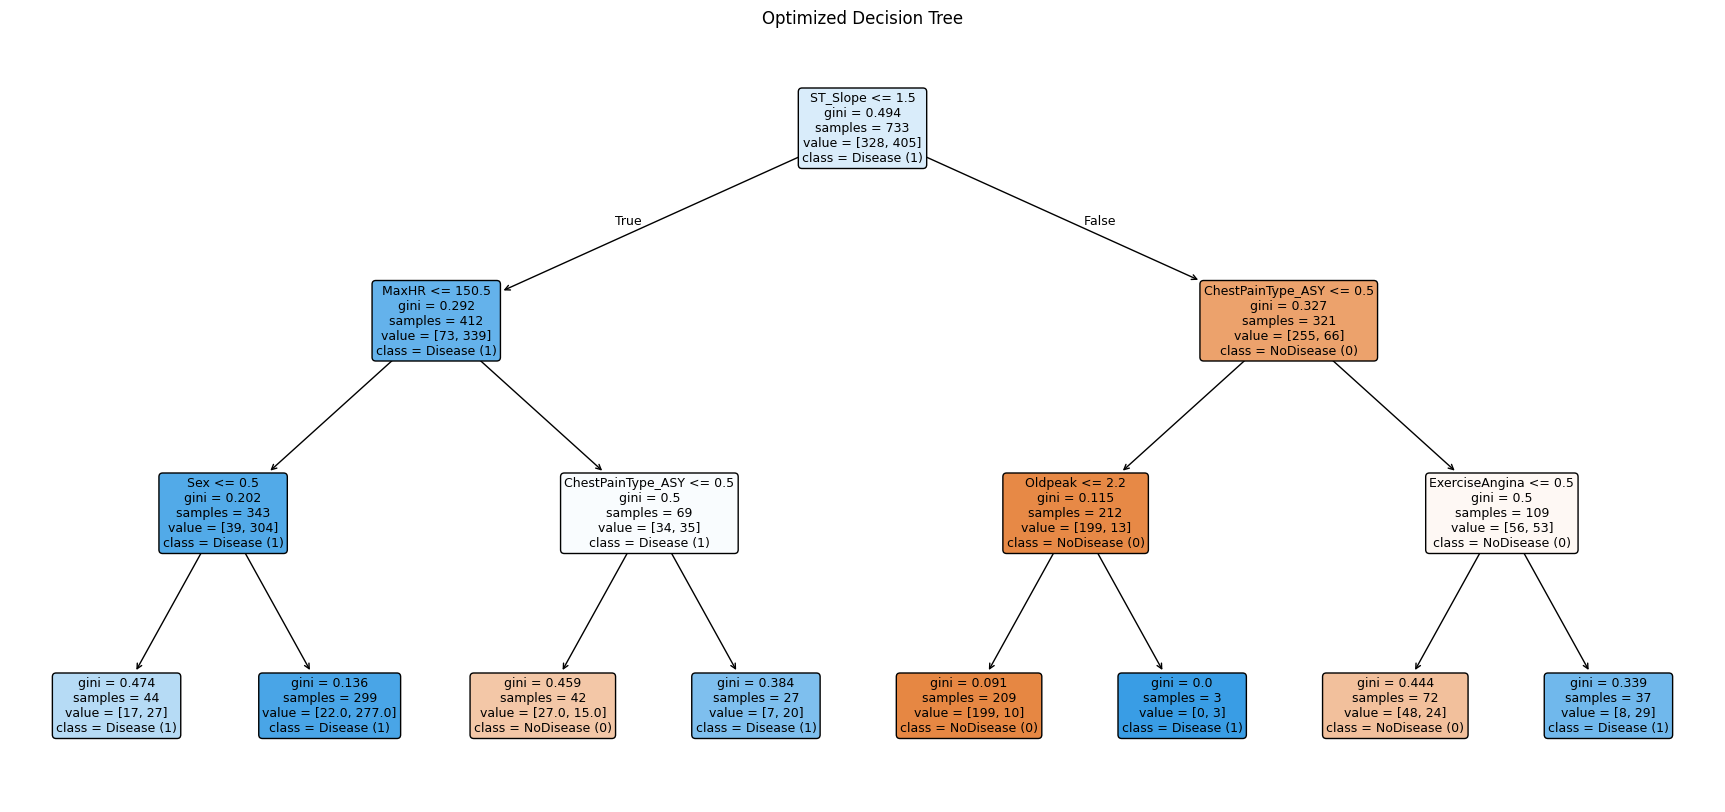

Top 10 Feature Importances:
ST_Slope             0.662194
ChestPainType_ASY    0.148524
MaxHR                0.079518
ExerciseAngina       0.047778
Sex                  0.036153
Oldpeak              0.025833
Cholesterol          0.000000
RestingBP            0.000000
FastingBS            0.000000
Age                  0.000000
dtype: float64


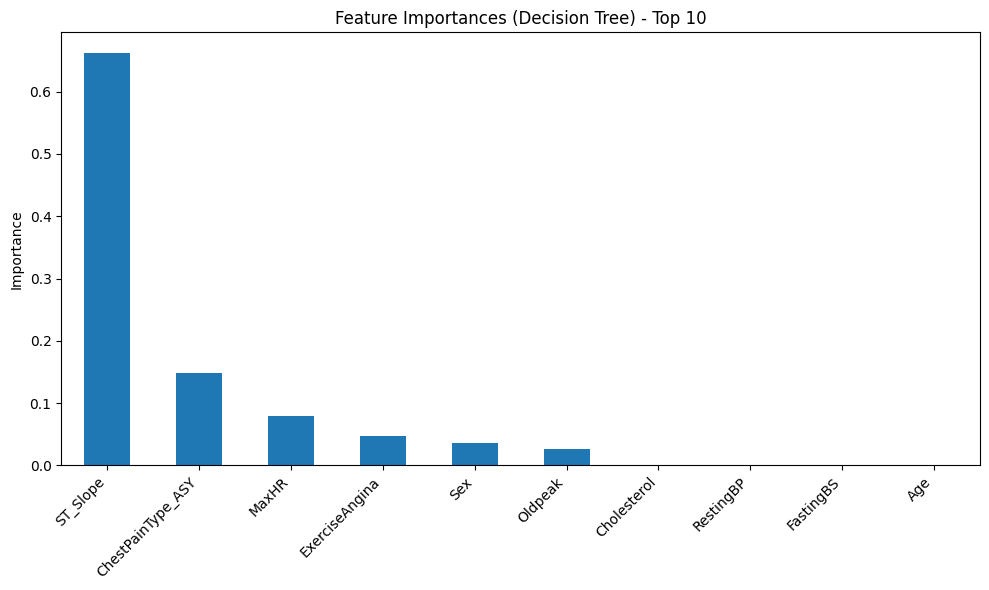

In [14]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(22, 10))                                                            #tree graph
plot_tree(
    dt_best,
    feature_names=X_train.columns,
    class_names=["NoDisease (0)", "Disease (1)"],
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title("Optimized Decision Tree")
plt.show()

importances = pd.Series(dt_best.feature_importances_, index=X_train.columns)             #important feature and barchart
importances_sorted = importances.sort_values(ascending=False)

print("Top 10 Feature Importances:")
print(importances_sorted.head(10))

top_k = 10
plt.figure(figsize=(10, 6))
importances_sorted.head(top_k).plot(kind="bar")
plt.title("Feature Importances (Decision Tree) - Top 10")
plt.ylabel("Importance")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()



Result:
Base on the tree the root node would be the most important feature cause of early split. So the ST_Slope and MaxHR and ChestPainType are the most important.
Base on the important features Barchart the first three important features are the same as what we impliment base on initially roots and parent in tree graph.

Feature importance in decision trees is computed based on the total reduction in node impurity contributed by each feature.

The Gini impurity used for splitting is defined as:

$$
Gini = 1 - \sum_{i=1}^{C} p_i^2
$$

For a given split, the impurity reduction is calculated as:

$$
\Delta Gini = Gini_{parent} -
\left(
\frac{n_L}{n} Gini_L +
\frac{n_R}{n} Gini_R
\right)
$$

The importance of a feature \( j \) is the sum of impurity reductions over all nodes where the feature is used:

$$
Importance(j) = \sum \Delta Gini_j
$$

Finally, importance values are normalized so that their sum equals one.


### **5. Random Forest**

Random Forest is an ensemble learning method that builds multiple decision trees using bootstrap samples of the training data. Each tree is trained independently, and at every split only a random subset of features is considered. This randomness increases model diversity and reduces variance.

In the implementation, a RandomForestClassifier is first trained as a baseline model using a fixed number of trees. Model performance is evaluated on both training and testing datasets to assess generalization.

To improve performance, hyperparameter tuning is performed using RandomizedSearchCV. Key parameters such as the number of trees (n_estimators), maximum tree depth (max_depth), and the number of features considered at each split (max_features) are optimized using cross-validation on the training data.

The final model is selected based on the best cross-validation performance and then evaluated on the test set. Compared to a single decision tree, the optimized random forest shows reduced overfitting and improved robustness to noise due to aggregation of predictions from multiple diverse trees.


In [15]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import RandomizedSearchCV

rf_model = RandomForestClassifier(
    n_estimators=100,      # number of trees
    random_state=1,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

y_train_pred = rf_model.predict(X_train)
y_test_pred  = rf_model.predict(X_test)

train_acc = accuracy_score(y_train, y_train_pred)
test_acc  = accuracy_score(y_test, y_test_pred)

print("Random Forest (Baseline)")
print(f"Train Accuracy: {train_acc:.4f}")
print(f"Test Accuracy : {test_acc:.4f}")
print(f"Gap           : {train_acc - test_acc:.4f}")



param_dist = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [None, 4, 6, 8, 10],
    "max_features": ["sqrt", "log2", 0.5]
}





rf = RandomForestClassifier(random_state=1)

random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_dist,
    n_iter=20,
    cv=5,
    scoring="accuracy",
    random_state=1,
    n_jobs=-1
)

random_search.fit(X_train, y_train)



best_rf = random_search.best_estimator_

train_acc = accuracy_score(y_train, best_rf.predict(X_train))
test_acc  = accuracy_score(y_test,  best_rf.predict(X_test))

print("Optimized Random Forest")
print("Best parameters:", random_search.best_params_)
print(f"Train Accuracy: {train_acc:.4f}")
print(f"Test Accuracy : {test_acc:.4f}")
print(f"Gap           : {train_acc - test_acc:.4f}")



Random Forest (Baseline)
Train Accuracy: 1.0000
Test Accuracy : 0.8424
Gap           : 0.1576
Optimized Random Forest
Best parameters: {'n_estimators': 200, 'max_features': 'log2', 'max_depth': 10}
Train Accuracy: 0.9918
Test Accuracy : 0.8424
Gap           : 0.1494


**First Question**: A single decision tree is highly sensitive to small changes in the training data, which results in high variance and often leads to overfitting. In Random Forest, each tree is trained on a different bootstrap sample of the data and considers a random subset of features at each split. As a result, individual trees make different errors. By averaging predictions (or using majority voting in classification), these uncorrelated errors tend to cancel each other out. This reduces the overall variance of the model and improves its ability to generalize to unseen data.

**Second Question**: Yes, Random Forest is more robust to noise than a single decision tree. A single tree can easily overfit noisy observations by creating very specific splits that capture random fluctuations rather than true patterns. In contrast, Random Forest trains many trees on different subsets of data and features, so noisy samples do not consistently influence all trees in the same way. Through majority voting, the impact of noise is reduced, leading to more stable and reliable predictions.

### **6. XGBoost**

XGBoost is a powerful ensemble learning algorithm based on the boosting paradigm. Unlike bagging methods such as Random Forest, where trees are trained independently, XGBoost builds trees sequentially. Each new tree is trained to correct the errors made by the previous trees. This sequential learning process allows the model to focus more on difficult samples and gradually improve overall performance.

XGBoost (Baseline)
Train Accuracy: 0.9809
Test Accuracy : 0.8696
Gap           : 0.1113


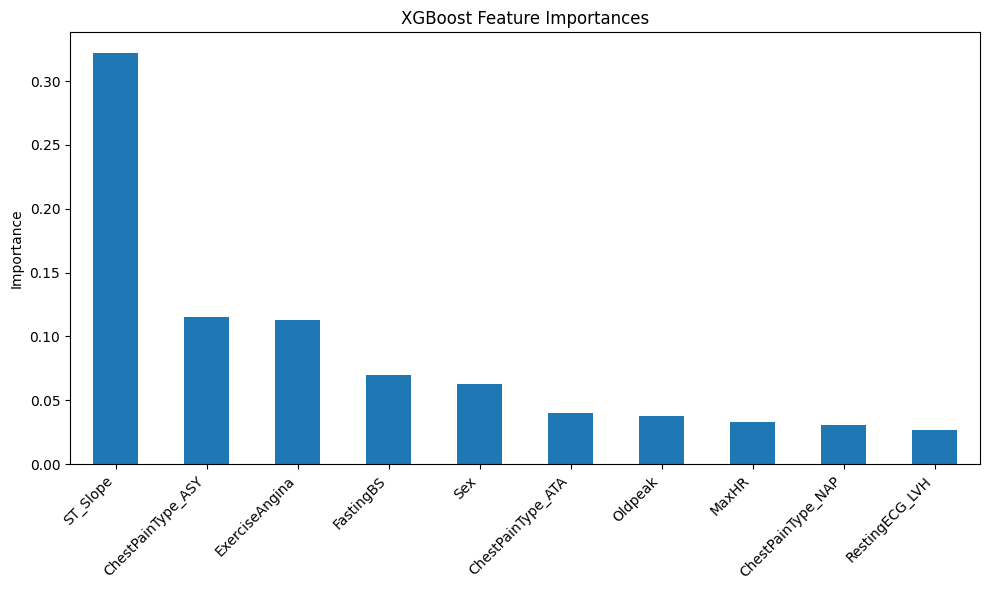

In [19]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

xgb_model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    random_state=1,
    eval_metric="logloss"
)

xgb_model.fit(X_train, y_train)

y_train_pred = xgb_model.predict(X_train)
y_test_pred  = xgb_model.predict(X_test)

train_acc = accuracy_score(y_train, y_train_pred)
test_acc  = accuracy_score(y_test,  y_test_pred)

print("XGBoost (Baseline)")
print(f"Train Accuracy: {train_acc:.4f}")
print(f"Test Accuracy : {test_acc:.4f}")
print(f"Gap           : {train_acc - test_acc:.4f}")



#Importatnt Features:

importances = pd.Series(                                 
    xgb_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)


top_k = 10
plt.figure(figsize=(10, 6))
importances.head(top_k).plot(kind="bar")
plt.ylabel("Importance")
plt.title("XGBoost Feature Importances")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


**What is the main difference between how trees are constructed in Random Forest and XGBoost?**
The main difference between Random Forest and XGBoost lies in the way decision trees are trained and combined.
In Random Forest, trees are built independently and in parallel. Each tree is trained on a bootstrap sample of the training data, and at each split only a random subset of features is considered. The final prediction is obtained by majority voting across all trees. This approach primarily aims to reduce model variance and mitigate overfitting, without considering interactions between trees.
In contrast, XGBoost constructs trees sequentially. Each new tree is trained to correct the errors made by the previous trees by focusing on the residuals of the current model. This boosting strategy allows XGBoost to progressively improve performance. Additionally, XGBoost incorporates an explicit loss function and regularization terms to control model complexity and reduce overfitting.
In summary, Random Forest reduces variance through averaging independent trees, while XGBoost improves performance by sequentially correcting errors and optimizing a global objective function.

**Are the important features identified by XGBoost the same as those in a simple decision tree? Why or why not?**
The important features identified by XGBoost are not necessarily the same as those identified by a simple decision tree.
In a single decision tree, feature importance is computed solely based on impurity reduction (such as Gini or entropy) within that one tree. As a result, features that appear near the root or in early splits often receive high importance, and the results can be sensitive to noise or small changes in the data.
In XGBoost, feature importance reflects the contribution of each feature to reducing the overall loss function across multiple sequentially trained trees. A feature may be used repeatedly across different trees to correct prediction errors, even if it is not dominant in the initial splits. Therefore, feature importance in XGBoost represents the aggregated effect of a feature over the entire boosting process.
The difference arises from the sequential learning mechanism, the use of loss-based optimization, and regularization in XGBoost, which enable it to capture more complex and subtle patterns compared to a single decision tree.

# <U>**Phase 3:**</U>

## **Final Evaluation and Analysis**

Let:
TP = True Positives  
TN = True Negatives  
FP = False Positives  
FN = False Negatives  

Accuracy:
$$
Accuracy = \frac{TP + TN}{TP + TN + FP + FN}
$$

Precision:
$$
Precision = \frac{TP}{TP + FP}
$$

Recall:
$$
Recall = \frac{TP}{TP + FN}
$$

F1-Score:
$$
F1 = 2 \times \frac{Precision \times Recall}{Precision + Recall}
$$

Macro Average:
$$
Macro = \frac{1}{C} \sum_{i=1}^{C} Metric_i
$$

Micro Average:
$$
Micro = \frac{\sum TP}{\sum TP + \sum FP + \sum FN}
$$

Weighted Average:
$$
Weighted = \sum_{i=1}^{C} w_i \times Metric_i
$$

where:
$$
w_i = \frac{\text{number of samples in class } i}{\text{total number of samples}}
$$

In [ ]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, classification_report

#Train Naive Bayes
nb_model = GaussianNB()
nb_model.fit(X_train_scaled, y_train)
y_pred_nb = nb_model.predict(X_test_scaled)


#Train Decision Tree
dt_model = DecisionTreeClassifier(random_state=1)
dt_model.fit(X_train, y_train)
y_pred_dt = dt_model.predict(X_test)

#Evaluation Function

def evaluate_model(name, y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, pos_label=1)
    rec = recall_score(y_true, y_pred, pos_label=1)
    f1 = f1_score(y_true, y_pred, pos_label=1)

    print("="*40)
    print(name)
    print("Confusion Matrix:")
    print(cm)
    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall   : {rec:.4f}")
    print(f"F1-Score : {f1:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, digits=4))


#Print Results

evaluate_model("Naive Bayes (GaussianNB)", y_test, y_pred_nb)
evaluate_model("Decision Tree (Default)", y_test, y_pred_dt)

Naive Bayes (GaussianNB)
Confusion Matrix:
[[58 24]
 [11 91]]
Accuracy : 0.8098
Precision: 0.7913
Recall   : 0.8922
F1-Score : 0.8387

Classification Report:
              precision    recall  f1-score   support

           0     0.8406    0.7073    0.7682        82
           1     0.7913    0.8922    0.8387       102

    accuracy                         0.8098       184
   macro avg     0.8159    0.7997    0.8035       184
weighted avg     0.8133    0.8098    0.8073       184

Decision Tree (Default)
Confusion Matrix:
[[59 23]
 [21 81]]
Accuracy : 0.7609
Precision: 0.7788
Recall   : 0.7941
F1-Score : 0.7864

Classification Report:
              precision    recall  f1-score   support

           0     0.7375    0.7195    0.7284        82
           1     0.7788    0.7941    0.7864       102

    accuracy                         0.7609       184
   macro avg     0.7582    0.7568    0.7574       184
weighted avg     0.7604    0.7609    0.7606       184



**What is the difference between Macro, Micro, and Weighted averaging for Precision, Recall, and F1-score?**
Macro averaging computes the evaluation metric independently for each class and then takes the unweighted average. This approach treats all classes equally, regardless of their frequency, and is useful for highlighting model performance on minority classes.

Micro averaging aggregates the contributions of all classes by summing true positives, false positives, and false negatives before computing the metric. As a result, micro averaging is dominated by the majority class and reflects overall classification performance.

Weighted averaging calculates the metric for each class and then weights each score by the number of true samples in that class. This method provides a balance between macro and micro averaging by accounting for class imbalance while still considering performance across all classes.

**In diagnosing dangerous diseases (such as heart disease), which is more important: Recall or Precision? Why?**
In the diagnosis of dangerous diseases such as heart disease, recall is generally more important than precision. Recall measures the model’s ability to correctly identify patients who actually have the disease. A false negative, where a diseased patient is incorrectly classified as healthy, can delay treatment and lead to severe or life-threatening consequences. While false positives may cause unnecessary follow-up tests, their impact is usually less critical than missing true disease cases.

**Based on the evaluation metrics, which model would you recommend for hospital use?**
For hospital use, the recommended model is the one that achieves high recall while maintaining a reasonable precision and a balanced F1-score on the test set. Models such as Random Forest or XGBoost are often preferable because they demonstrate stronger generalization performance, higher robustness to noise, and better recall compared to simpler models. These properties make them more suitable for clinical decision support systems where patient safety is the highest priority.